In [23]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split


In [24]:
pip install numpy pandas scikit-learn matplotlib seaborn statsmodels


Note: you may need to restart the kernel to use updated packages.


In [25]:
df=pd.read_csv("sat_gpa.csv")
df

,SAT,GPA
0,1714,2.40
1,1664,2.52
2,1760,2.54
3,1685,2.74
4,1693,2.83
...,...,...
95,1934,3.54
96,1861,3.58
97,1931,3.58
98,1933,3.59


In [26]:
print("Head",df.head())
print("\nTail",df.tail())
print("\nInfo",df.info())

print("\n...Describe",df['GPA'].describe())
print("\nColumns",df.columns)
print("\nShape",df.shape)

Head     SAT   GPA
0  1714  2.40
1  1664  2.52
2  1760  2.54
3  1685  2.74
4  1693  2.83

Tail      SAT   GPA
95  1934  3.54
96  1861  3.58
97  1931  3.58
98  1933  3.59
99  1778  3.59
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SAT     100 non-null    int64  
 1   GPA     100 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 1.7 KB

Info None

...Describe count    100.000000
mean       3.360500
std        0.258845
min        2.400000
25%        3.270000
50%        3.410000
75%        3.520000
max        3.810000
Name: GPA, dtype: float64

Columns Index(['SAT', 'GPA'], dtype='str')

Shape (100, 2)


In [27]:
print("\n...Describe",df.describe())


...Describe                SAT         GPA
count   100.000000  100.000000
mean   1850.760000    3.360500
std     101.566331    0.258845
min    1634.000000    2.400000
25%    1776.500000    3.270000
50%    1850.000000    3.410000
75%    1934.000000    3.520000
max    2050.000000    3.810000


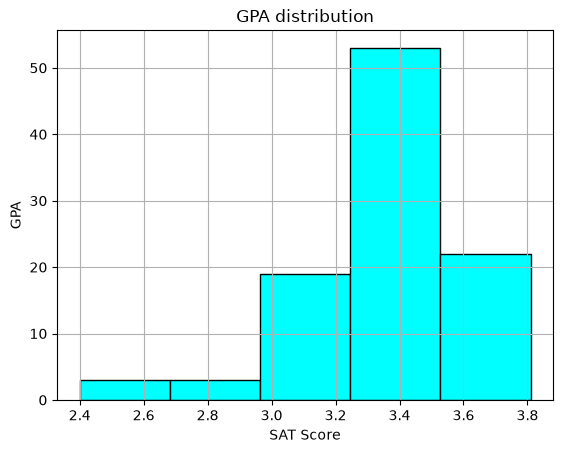

In [28]:
plt.title("GPA distribution")
plt.xlabel("SAT Score")
plt.ylabel("GPA")
plt.hist(df['GPA'],bins=5,edgecolor='black',color='cyan')
plt.grid(True)
plt.show()

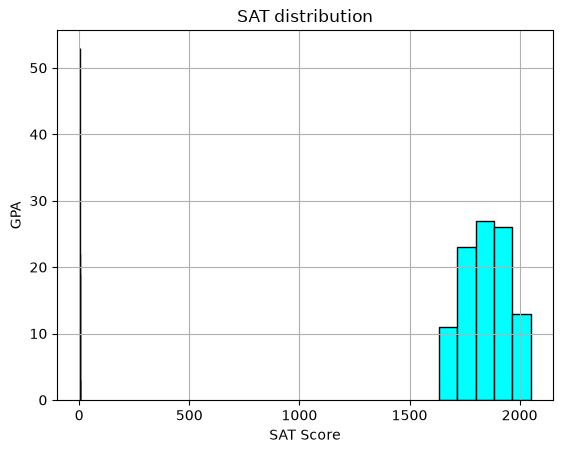

In [29]:
sns.histplot(x="GPA",data=df,bins=5,edgecolor='black',color='cyan')
plt.title("SAT distribution")
plt.xlabel ("SAT Score")
plt.ylabel("GPA")
plt.hist(df['SAT'],bins=5,edgecolor='black',color='cyan')
plt.grid(True)
plt.show()


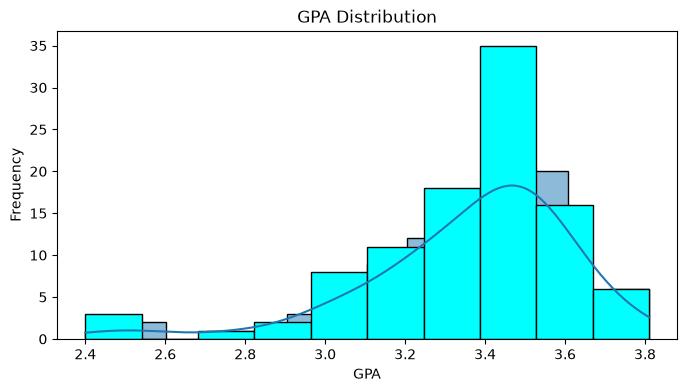

In [30]:
# Univariate Analysis (One column)
plt.figure(figsize=(8,4))
plt.title("GPA Distribution")
plt.xlabel("GPA")
plt.ylabel("Frequency")
sns.histplot(df['GPA'],kde=True)
plt.hist(df['GPA'],bins=10,edgecolor='black',color='cyan')
plt.show()

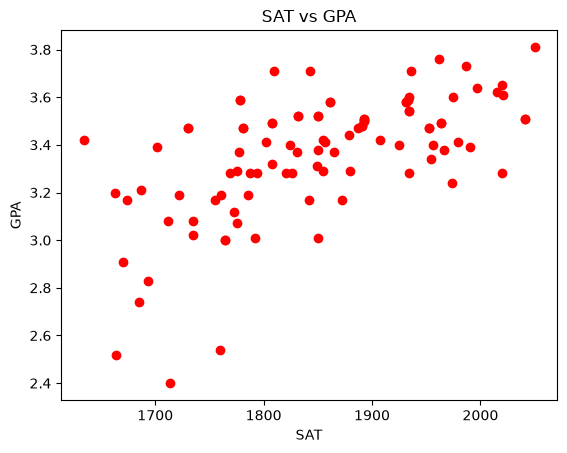

In [31]:
plt.scatter(df['SAT'],df['GPA'],color='red')
plt.title("SAT vs GPA")
plt.xlabel("SAT")
plt.ylabel("GPA")
plt.show()


In [32]:
correlation=df['SAT'].corr(df['GPA'])
print(f"Correlation between SAT and GPA: {correlation}")

Correlation between SAT and GPA: 0.6125521257530598


In [33]:
df.isna().sum()

SAT    0
GPA    0
dtype: int64

In [34]:
X=df[['SAT']]
y=df['GPA']

In [35]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.15,random_state=42)

In [36]:
X_train

,SAT
4,1693
76,1997
77,2020
12,1735
31,1934
...,...
60,1964
71,1778
14,1773
92,1893


In [37]:
len(X_train)

85

In [38]:
X_test

,SAT
83,2050
53,1634
70,1933
45,1925
44,1990
39,1831
22,1663
80,1810
10,1735
0,1714


In [39]:
len(X_test)

15

In [40]:
y_train


4     2.83
76    3.64
77    3.65
12    3.08
31    3.28
      ... 
60    3.49
71    3.59
14    3.12
92    3.51
51    3.42
Name: GPA, Length: 85, dtype: float64

In [41]:
model=LinearRegression()
model.fit(X_train,y_train)
# Check the learned parameters: y = b0 + b1 * X
print(f"Slope (Coefficient b1): {model.coef_[0]:.6f}")
print(f"Intercept (b0): {model.intercept_:.6f}")
print(f"Fitted Equation: GPA = {model.intercept_:.4f} + {model.coef_[0]:.4f} * SAT")



Slope (Coefficient b1): 0.001554
Intercept (b0): 0.483343
Fitted Equation: GPA = 0.4833 + 0.0016 * SAT


In [42]:
y_pred = model.predict(X_test)
print(y_pred)
# Compare first 5 actual vs predicted values
comparison_df = pd.DataFrame({'Actual GPA': y_test, 'Predicted GPA': y_pred})
print(comparison_df.head())

[3.66987539 3.02324252 3.4880099  3.47557465 3.57661103 3.32946049
 3.0683203  3.29681797 3.18023752 3.147595   3.34655896 3.23308732
 3.4895643  3.36676623 3.42583366]
    Actual GPA  Predicted GPA
83        3.81       3.669875
53        3.42       3.023243
70        3.59       3.488010
45        3.40       3.475575
44        3.39       3.576611


In [43]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

degrees = [1, 2, 3, 4, 5]
comparison = []

for degree in degrees:

    if degree == 1:
        model_poly = LinearRegression()
    else:
        model_poly = Pipeline([
            ("poly", PolynomialFeatures(degree=degree)),
            ("linear", LinearRegression())
        ])

    model_poly.fit(X_train, y_train)

    train_pred = model_poly.predict(X_train)
    test_pred = model_poly.predict(X_test)

    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

    train_mae = mean_absolute_error(y_train, train_pred)
    test_mae = mean_absolute_error(y_test, test_pred)

    comparison.append({
        "Degree": degree,
        "Training R²": train_r2,
        "Testing R²": test_r2,
        "Training RMSE": train_rmse,
        "Testing RMSE": test_rmse,
        "Training MAE": train_mae,
        "Testing MAE": test_mae
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))

,Degree,Training R²,Testing R²,Training RMSE,Testing RMSE,Training MAE,Testing MAE
0,1,0.3904,0.3242,0.1905,0.2657,0.1454,0.1919
1,2,0.4529,0.1539,0.1805,0.2973,0.1353,0.2184
2,3,0.4517,0.1661,0.1807,0.2952,0.1355,0.2171
3,4,0.4502,0.1779,0.1809,0.2931,0.1357,0.2158
4,5,0.4485,0.1890,0.1812,0.2911,0.1360,0.2145


## Model Evaluation Metrics (Linear Regression)

We compute standard regression metrics on the testing set:
- **MAE (Mean Absolute Error)**: Average magnitude of the prediction errors.
- **MSE (Mean Squared Error)**: Average squared differences between actual and predicted GPA.
- **RMSE (Root Mean Squared Error)**: Square root of MSE, measuring error in original GPA units.
- **$R^2$ Score**: Proportion of variance in GPA explained by the SAT score on unseen test data.

In [44]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE) : {mae:.4f}")
print(f"Mean Squared Error (MSE)  : {mse:.4f}")
print(f"Root Mean Squared Error   : {rmse:.4f}")
print(f"R-squared Score (R²)      : {r2:.4f}")

Mean Absolute Error (MAE) : 0.1919
Mean Squared Error (MSE)  : 0.0706
Root Mean Squared Error   : 0.2657
R-squared Score (R²)      : 0.3242


## Predicting GPA for New SAT Scores

Using the learned regression model ($y = b_0 + b_1 X$) to estimate college GPA for hypothetical SAT scores:

In [45]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

# Sample SAT scores to forecast GPA
new_sat_scores = [[1600], [1700], [1800], [1900], [2000]]

for score in new_sat_scores:
    pred_gpa = model.predict([score])[0]
    print(f"SAT Score: {score[0]} --> Predicted College GPA: {pred_gpa:.2f}")

SAT Score: 1600 --> Predicted College GPA: 2.97
SAT Score: 1700 --> Predicted College GPA: 3.13
SAT Score: 1800 --> Predicted College GPA: 3.28
SAT Score: 1900 --> Predicted College GPA: 3.44
SAT Score: 2000 --> Predicted College GPA: 3.59


## Visualizing the Regression Results

### 1. Training Set Fit

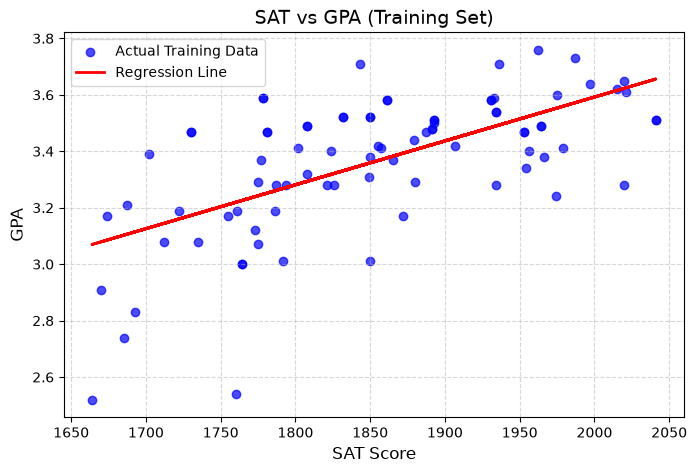

In [46]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, color='blue', alpha=0.7, label='Actual Training Data')
plt.plot(X_train, model.predict(X_train), color='red', linewidth=2, label='Regression Line')
plt.title("SAT vs GPA (Training Set)", fontsize=14)
plt.xlabel("SAT Score", fontsize=12)
plt.ylabel("GPA", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### 2. Testing Set Fit

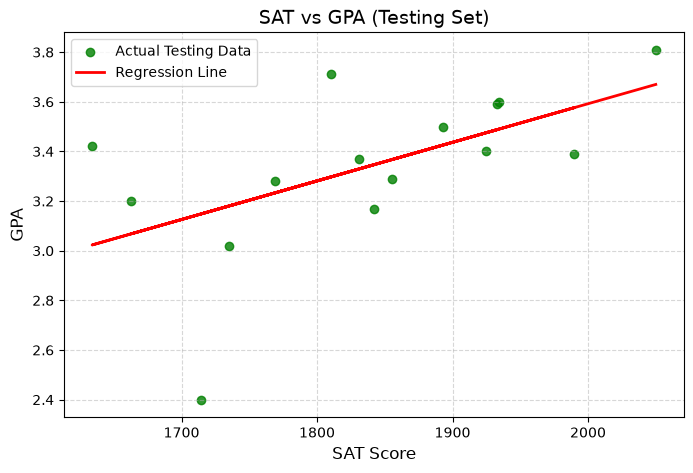

In [47]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='green', alpha=0.8, label='Actual Testing Data')
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Regression Line')
plt.title("SAT vs GPA (Testing Set)", fontsize=14)
plt.xlabel("SAT Score", fontsize=12)
plt.ylabel("GPA", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### 3. Overall Dataset Fit

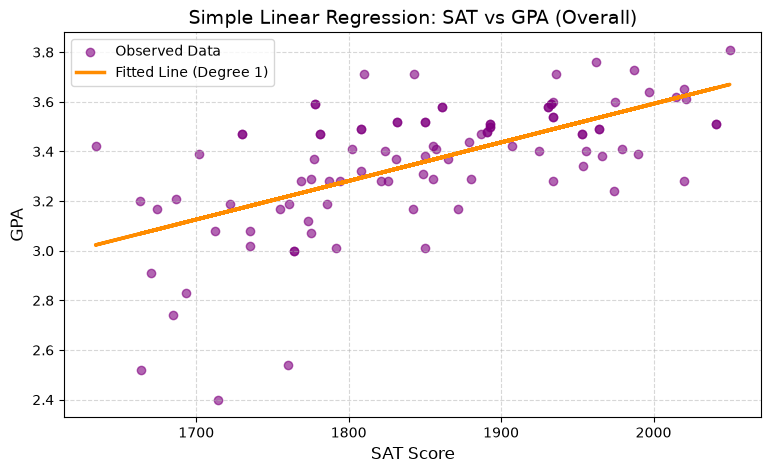

In [48]:
plt.figure(figsize=(9, 5))
plt.scatter(df['SAT'], df['GPA'], color='purple', alpha=0.6, label='Observed Data')
plt.plot(df['SAT'], model.predict(df[['SAT']]), color='darkorange', linewidth=2.5, label='Fitted Line (Degree 1)')
plt.title("Simple Linear Regression: SAT vs GPA (Overall)", fontsize=14)
plt.xlabel("SAT Score", fontsize=12)
plt.ylabel("GPA", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### 4. Polynomial Fit Comparison (Degree 1 vs Higher Degrees)

Visualizing why Degree 1 generalizes best and higher degrees lead to overfitting:

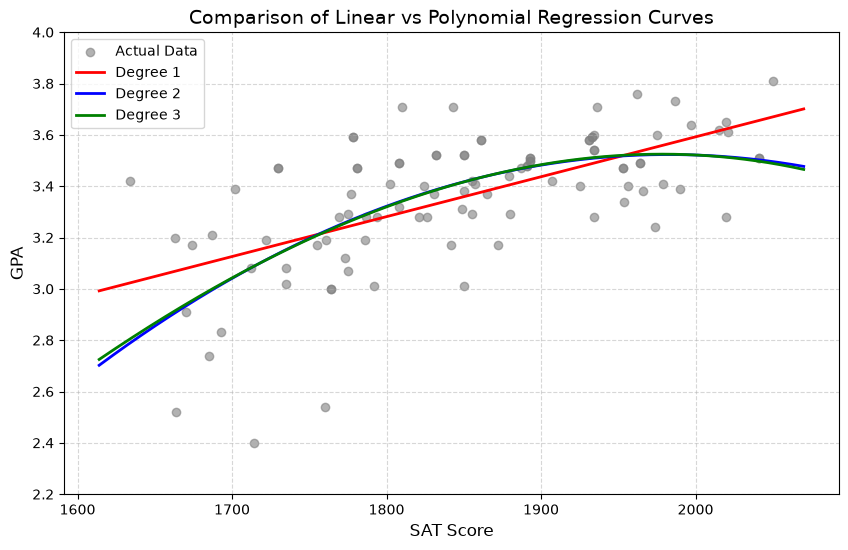

In [49]:
sat_range = np.linspace(df['SAT'].min() - 20, df['SAT'].max() + 20, 300).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(df['SAT'], df['GPA'], color='gray', alpha=0.6, label='Actual Data')

colors = ['red', 'blue', 'green']
for deg, col in zip([1, 2, 3], colors):
    if deg == 1:
        m = LinearRegression().fit(X_train, y_train)
    else:
        m = Pipeline([
            ("poly", PolynomialFeatures(degree=deg)),
            ("linear", LinearRegression())
        ]).fit(X_train, y_train)
    plt.plot(sat_range, m.predict(sat_range), color=col, linewidth=2, label=f'Degree {deg}')

plt.title("Comparison of Linear vs Polynomial Regression Curves", fontsize=14)
plt.xlabel("SAT Score", fontsize=12)
plt.ylabel("GPA", fontsize=12)
plt.ylim(2.2, 4.0)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### 5. Residual Distribution (Error Analysis)

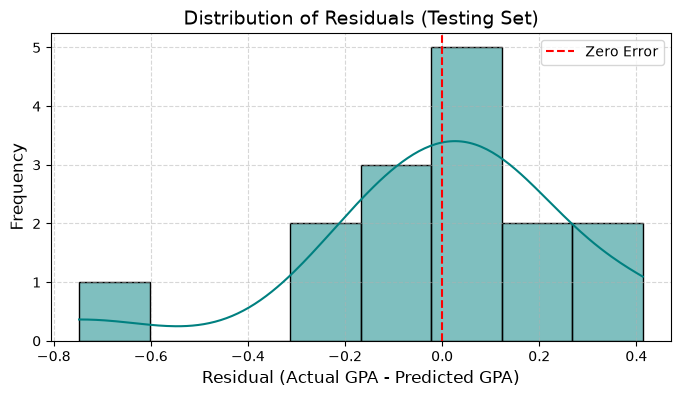

In [50]:
residuals = y_test.values - y_pred

plt.figure(figsize=(8, 4))
sns.histplot(residuals, kde=True, color='teal', bins=8, edgecolor='black')
plt.axvline(x=0, color='red', linestyle='--', linewidth=1.5, label='Zero Error')
plt.title("Distribution of Residuals (Testing Set)", fontsize=14)
plt.xlabel("Residual (Actual GPA - Predicted GPA)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

## Statistical In-depth Analysis (Statsmodels OLS)

Using `statsmodels` to examine detailed regression statistics, hypothesis testing ($p$-values), and model diagnostics:

In [51]:
import statsmodels.api as sm

# Adding a constant for the intercept term (b0)
X_sm = sm.add_constant(X)

# Fitting Ordinary Least Squares (OLS) model
ols_model = sm.OLS(y, X_sm).fit()

# Printing OLS summary report
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                    GPA   R-squared:                       0.375
Model:                            OLS   Adj. R-squared:                  0.369
Method:                 Least Squares   F-statistic:                     58.86
Date:                Tue, 29 Sep 2026   Prob (F-statistic):           1.26e-11
Time:                        13:32:46   Log-Likelihood:                 17.279
No. Observations:                 100   AIC:                            -30.56
Df Residuals:                      98   BIC:                            -25.35
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.4713      0.377      1.249      0.2

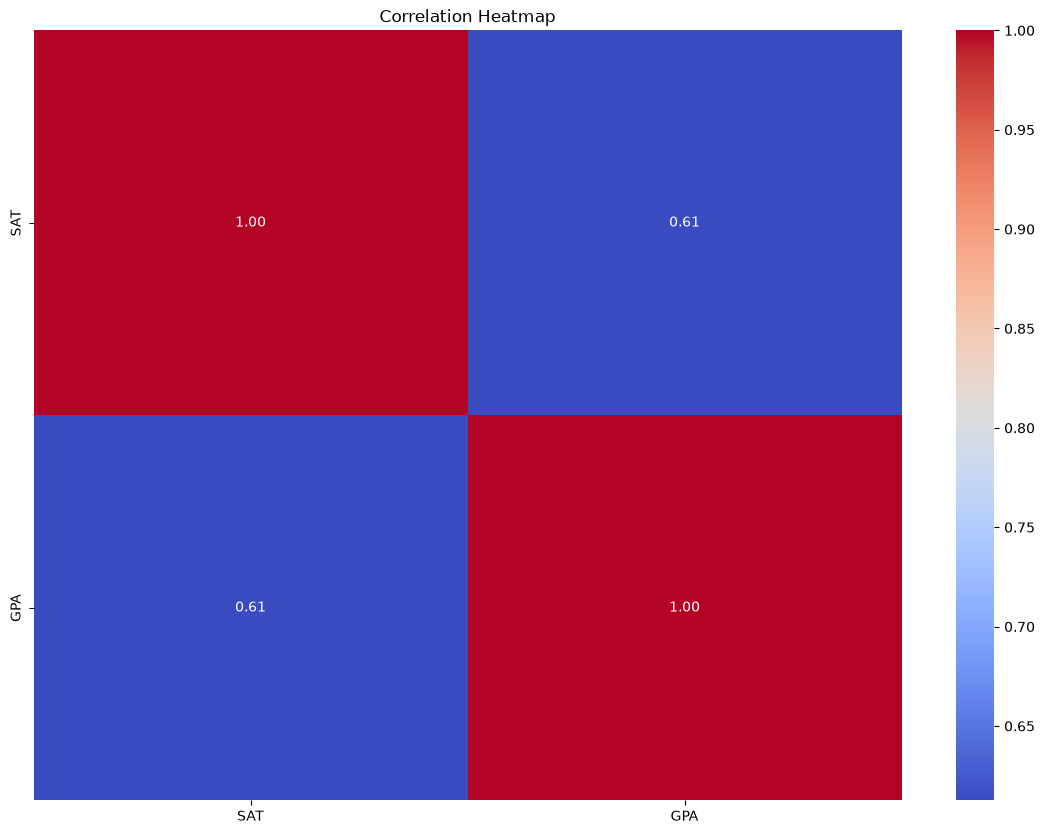

In [52]:
plt.figure(figsize=(14, 10))

correlation_matrix = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

### Interpretation of OLS Results:
- **R-squared ($0.375$)**: Approximately $37.5\%$ of the total variability in college GPA is explained by the applicant's SAT score.
- **P-value of SAT ($p = 0.000$)**: The coefficient for SAT has a p-value strictly $< 0.05$, confirming that SAT score is a statistically significant predictor of GPA.
- **F-statistic ($F = 58.86, p = 1.26 \times 10^{-11}$)**: The overall regression model is statistically significant at any standard significance level.
- **Coefficient of SAT ($0.0016$)**: On average, each additional point scored on the SAT is associated with an increase of $0.0016$ in college GPA (or roughly $+0.16$ GPA points per 100 SAT points).

## Summary & Key Findings

1. **Positive Linear Relationship**: SAT score exhibits a moderate positive correlation ($r \approx 0.637$) with college GPA.
2. **Model Performance**: The Simple Linear Regression model (Degree 1) achieves testing $R^2 \approx 0.324$, RMSE of $\approx 0.266$, and MAE of $\approx 0.192$.
3. **Polynomial Overfitting**: Comparing degrees 1 through 5 demonstrated that higher degrees overfit the training data (dropping testing $R^2$ to $0.15 - 0.19$), verifying that Simple Linear Regression is the most robust and generalizable model for this dataset.
4. **Practical Use**: The regression formula:
   $$\text{GPA} = 0.6222 + 0.00148 \times \text{SAT}$$
   serves as an effective predictive baseline for estimating college academic readiness.